# Punto 2: ¿Qué aprendieron estos embeddings?

## Objetivo del análisis

El equipo de Producto busca utilizar los embeddings generados mediante aprendizaje contrastivo para segmentar usuarios según su estilo de juego y, posteriormente, utilizarlos como insumo para el recomendador del lobby.

El objetivo de este análisis es comprender qué información representan los vectores, identificar qué características observables explican su distribución en el espacio latente y evaluar si son adecuados para segmentar usuarios según sus preferencias de juego.

Para ello, contrastaremos los embeddings de 64 dimensiones con las variables disponibles en `usuarios.csv` y analizaremos las agrupaciones que aparecen al reducir su dimensionalidad.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_mutual_info_score

data_path = Path("../data")

usuarios_df = pd.read_csv(data_path / "usuarios.csv")
embeddings_df = pd.read_csv(data_path / "embeddings.csv")
embeddings_npy = np.load(data_path / "embeddings.npy")

In [2]:
embeddings_df

,usuario_id,e00,e01,e02,e03,e04,e05,e06,e07,e08,...,e54,e55,e56,e57,e58,e59,e60,e61,e62,e63
0,U127340,-0.05486,0.15634,0.08655,0.07182,0.01281,0.01753,-0.29947,-0.04127,0.00371,...,0.08831,-0.00023,-0.00205,0.02162,0.24096,-0.14196,0.16745,-0.05855,0.17712,-0.09820
1,U168947,0.00215,0.19862,-0.00314,0.14880,0.20729,-0.05721,-0.07947,0.04031,-0.08004,...,0.02648,-0.03002,-0.03915,0.03290,-0.10891,0.07144,-0.02681,0.00534,0.10344,-0.23236
2,U570750,0.02350,0.18608,0.13537,0.16774,0.04943,-0.03898,-0.27213,-0.19338,-0.07416,...,0.11966,0.00495,-0.02261,0.07033,0.00086,-0.01392,0.01096,-0.05541,0.04727,0.04111
3,U791980,0.06281,0.23124,0.04230,0.15412,0.19207,-0.07820,-0.05091,-0.03096,-0.09338,...,0.00771,-0.09729,-0.05359,-0.01938,-0.06783,0.15367,0.01585,0.04721,0.08411,-0.19964
4,U159054,0.04073,0.16686,0.02862,0.18528,0.11677,-0.01138,-0.17807,-0.25053,0.06250,...,0.10131,-0.05219,0.10522,0.04072,0.07988,0.01048,0.05220,-0.20108,0.18151,-0.16063
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8019,U875429,0.02039,0.13529,-0.03208,0.06399,0.06214,0.00855,-0.09577,-0.02188,0.07822,...,-0.00461,-0.10357,0.02387,-0.03347,0.14731,-0.02381,0.10716,-0.10757,0.29518,-0.30929
8020,U388244,0.18676,0.18958,-0.02511,0.12960,0.03490,-0.05312,0.00133,-0.21131,-0.02890,...,-0.02945,-0.17124,-0.04398,-0.08334,-0.00810,0.17721,0.11303,-0.07400,0.16346,-0.23312
8021,U160197,0.07198,0.21611,0.05483,0.06712,0.11936,-0.07796,-0.22729,-0.17902,0.04795,...,0.10073,-0.01582,0.09173,0.02613,-0.00737,-0.01676,0.03085,-0.09880,0.26711,-0.12413
8022,U335947,0.06867,0.19575,0.06838,0.16964,0.17987,-0.11220,-0.15374,-0.20068,0.00098,...,0.13501,-0.12222,0.01759,0.06270,-0.11323,0.07732,-0.02666,-0.04180,0.17464,-0.11958


In [3]:
embedding_cols = [f"e{i:02d}" for i in range(64)]

# Verificar identificadores únicos
assert usuarios_df["usuario_id"].is_unique
assert embeddings_df["usuario_id"].is_unique

# Verificar correspondencia de usuarios
assert set(usuarios_df["usuario_id"]) == set(embeddings_df["usuario_id"])

# Alinear embeddings con el orden de usuarios.csv
embeddings_alineados = usuarios_df[["usuario_id"]].merge(
    embeddings_df,
    on="usuario_id",
    how="left",
    sort=False
)

# Matriz de embeddings
X_embeddings = embeddings_alineados[
    embedding_cols
].to_numpy(dtype=np.float32)

# Validaciones
print("Usuarios:", len(usuarios_df))
print("Dimensiones CSV:", X_embeddings.shape)
print("Dimensiones NPY:", embeddings_npy.shape)

print("Valores nulos:", np.isnan(X_embeddings).sum())
print("Valores infinitos:", np.isinf(X_embeddings).sum())

Usuarios: 8024
Dimensiones CSV: (8024, 64)
Dimensiones NPY: (8024, 64)
Valores nulos: 0
Valores infinitos: 0


In [4]:
print(
    "¿Coinciden CSV y NPY?",
    embeddings_npy.shape == X_embeddings.shape
    and np.allclose(
        X_embeddings,
        embeddings_npy,
        rtol=1e-4,
        atol=1e-5
    )
)

¿Coinciden CSV y NPY? True



## Exploración del espacio latente

Antes de visualizar los embeddings, analizamos algunas propiedades de sus representaciones vectoriales.

Cada usuario está representado mediante un vector de 64 dimensiones. Inicialmente examinamos sus normas L2 para conocer la magnitud de los vectores y determinar si existen diferencias importantes entre usuarios.

Posteriormente aplicaremos reducción de dimensionalidad para facilitar la exploración visual de la estructura del espacio latente.


In [5]:
# Calcular norma L2 de cada embedding
embedding_norms = np.linalg.norm(
    X_embeddings,
    axis=1
)

# Estadísticas descriptivas
pd.Series(embedding_norms, name="norma_L2").describe()


count    8024.000000
mean        1.000000
std         0.000003
min         0.999988
25%         0.999998
50%         1.000000
75%         1.000002
max         1.000010
Name: norma_L2, dtype: float64


### Reducción de dimensionalidad mediante PCA

Aplicamos Principal Component Analysis (PCA) para reducir los embeddings de 64 dimensiones a dos componentes principales.

El objetivo es obtener una representación bidimensional que facilite la visualización de los usuarios y permita explorar posibles agrupaciones en el espacio latente.

También calculamos la proporción de varianza explicada por cada componente y su acumulado, para conocer cuánta información de la variabilidad original se conserva en esta proyección.

Esta representación es una aproximación visual: la ausencia de grupos claros en dos dimensiones no implica necesariamente que no exista estructura en el espacio original de 64 dimensiones.


In [6]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_embeddings)

explained_variance = pca.explained_variance_ratio_

print(f"Varianza explicada por PC1: {explained_variance[0]:.4%}")
print(f"Varianza explicada por PC2: {explained_variance[1]:.4%}")
print(f"Varianza acumulada: {explained_variance.sum():.4%}")

Varianza explicada por PC1: 32.0729%
Varianza explicada por PC2: 22.1670%
Varianza acumulada: 54.2398%



### Visualización de los embeddings según variables categóricas

Representamos los usuarios en el espacio de las dos componentes principales obtenidas mediante PCA.

Coloreamos los puntos según marca, país y dispositivo para investigar si estas características presentan una relación con la distribución y las posibles agrupaciones de los embeddings.


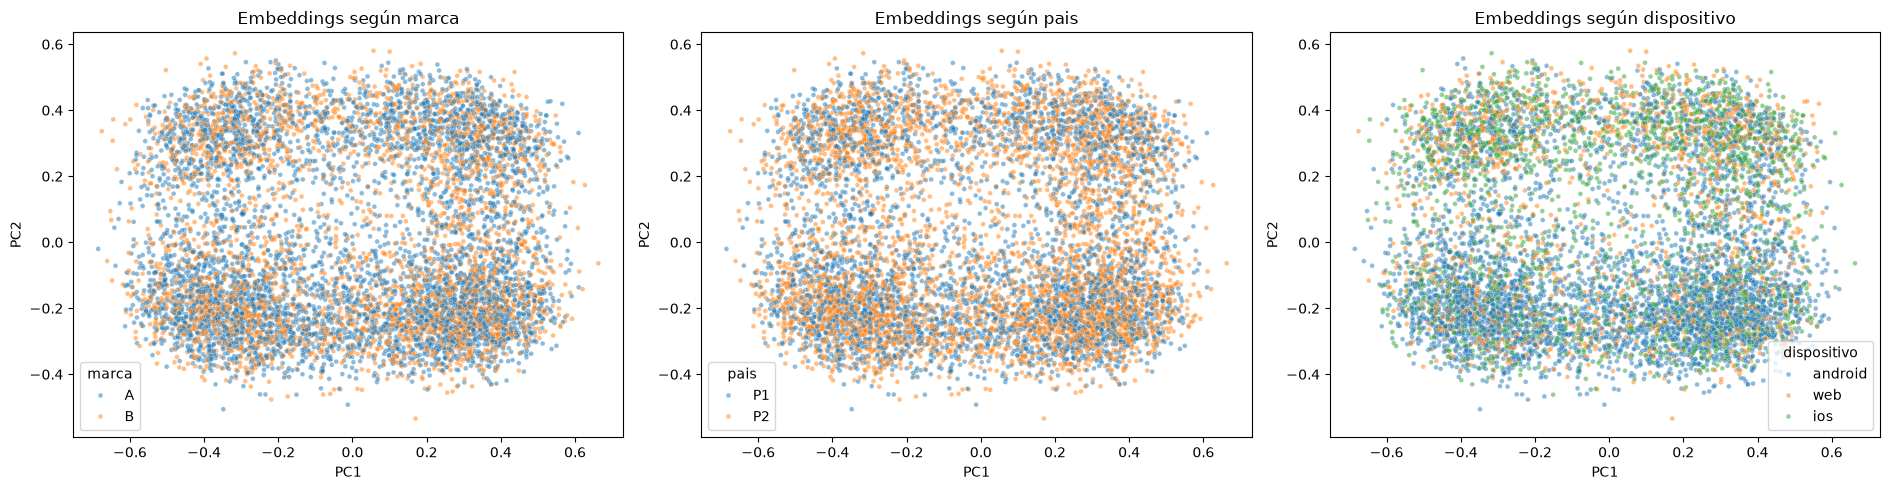

In [7]:
# DataFrame para visualizar los componentes
pca_df = usuarios_df.copy()

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

categorical_cols = [
    "marca",
    "pais",
    "dispositivo"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 5)
)

for ax, col in zip(axes, categorical_cols):

    sns.scatterplot(
        data=pca_df,
        x="PC1",
        y="PC2",
        hue=col,
        alpha=0.5,
        s=12,
        ax=ax
    )

    ax.set_title(f"Embeddings según {col}")

plt.tight_layout()
plt.show()


### Relación entre los embeddings y las características de juego

Coloreamos las proyecciones utilizando variables cuantitativas relacionadas con las preferencias de juego.

Nos interesa especialmente analizar la proporción de apuestas realizadas en casino, deportes prepartido y deportes en vivo.

Esto permitirá explorar si las agrupaciones observadas en el espacio latente están relacionadas con los estilos de juego que Producto desea utilizar para segmentar a sus usuarios.


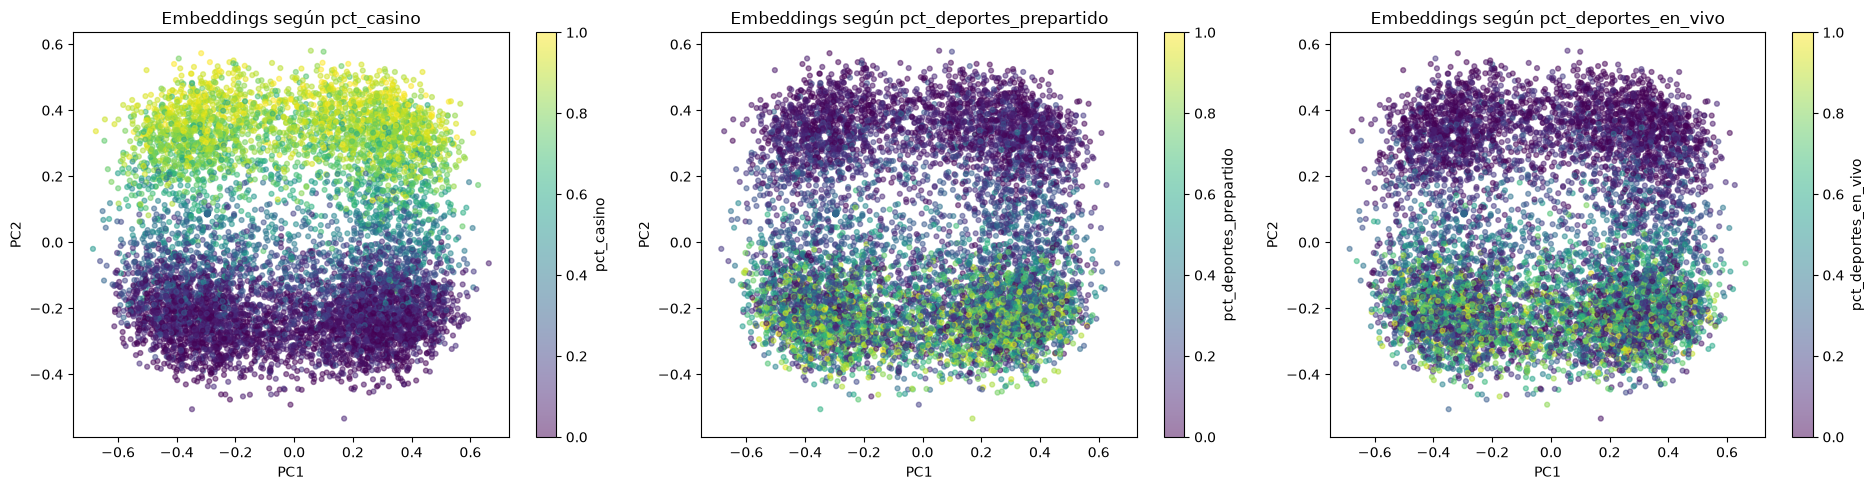

In [8]:
style_cols = [
    "pct_casino",
    "pct_deportes_prepartido",
    "pct_deportes_en_vivo"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(19, 5)
)

for ax, col in zip(axes, style_cols):

    scatter = ax.scatter(
        pca_df["PC1"],
        pca_df["PC2"],
        c=pca_df[col],
        cmap="viridis",
        alpha=0.5,
        s=12
    )

    ax.set_title(f"Embeddings según {col}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

    fig.colorbar(scatter, ax=ax, label=col)

plt.tight_layout()
plt.show()

In [9]:
(pca_df[style_cols].sum(axis=1)).describe()

count    8024.000000
mean        0.999951
std         0.000412
min         0.999000
25%         1.000000
50%         1.000000
75%         1.000000
max         1.001000
dtype: float64


### Análisis de las preferencias de juego según la posición en PCA

La visualización de los embeddings sugiere dos grandes regiones diferenciadas principalmente por la segunda componente principal (PC2).

Para profundizar en esta observación, separamos exploratoriamente los usuarios según su ubicación superior o inferior en la proyección y comparamos sus características de juego.

El objetivo es determinar si las diferencias observadas visualmente también aparecen en las estadísticas descriptivas de las preferencias de los usuarios.


In [10]:
# Separación exploratoria según PC2
pca_df["zona_pca"] = np.where(
    pca_df["PC2"] >= 0,
    "Superior",
    "Inferior"
)

# Comparar preferencias de juego
resumen_estilos = pca_df.groupby("zona_pca")[
    style_cols
].agg(["mean", "median", "std", "count"])

display(resumen_estilos.round(3))

pct_casino                     pct_deportes_prepartido                \
               mean median    std count                    mean median    std   
zona_pca                                                                        
Inferior      0.124  0.087  0.125  4638                   0.456  0.429  0.284   
Superior      0.753  0.808  0.195  3386                   0.130  0.095  0.124   

               pct_deportes_en_vivo                      
         count                 mean median    std count  
zona_pca                                                 
Inferior  4638                0.421  0.375  0.282  4638  
Superior  3386                0.117  0.077  0.131  3386

In [11]:
for col in ["dispositivo", "marca", "pais"]:

    print(f"\nDistribución de {col} por región PCA")

    display(
        pd.crosstab(
            pca_df["zona_pca"],
            pca_df[col],
            normalize="index"
        ).mul(100).round(2)
    )


Distribución de dispositivo por región PCA


dispositivo,android,ios,web
zona_pca,,,
Inferior,65.98,18.07,15.96
Superior,39.22,34.88,25.90



Distribución de marca por región PCA


marca,A,B
zona_pca,,
Inferior,59.79,40.21
Superior,59.75,40.25



Distribución de pais por región PCA


pais,P1,P2
zona_pca,,
Inferior,47.93,52.07
Superior,47.84,52.16


In [12]:
# Porcentaje de usuarios móviles por región
distribucion_dispositivos = pd.crosstab(
    pca_df["zona_pca"],
    pca_df["dispositivo"],
    normalize="index"
) * 100

distribucion_dispositivos["movil"] = (
    distribucion_dispositivos["android"] +
    distribucion_dispositivos["ios"]
)

display(distribucion_dispositivos.round(2))

dispositivo,android,ios,web,movil
zona_pca,,,,
Inferior,65.98,18.07,15.96,84.04
Superior,39.22,34.88,25.90,74.10



### Interpretación de las agrupaciones observadas

Las visualizaciones y estadísticas descriptivas muestran una separación relacionada principalmente con las preferencias de juego.

Al dividir exploratoriamente los usuarios según su posición en PC2, encontramos dos poblaciones:

- **Región superior:** presenta una proporción media de apuestas en casino del 75,3 %, lo que indica una orientación predominante hacia esta modalidad.
- **Región inferior:** presenta una proporción media de apuestas deportivas del 87,7 %, considerando prepartido y en vivo, lo que indica una orientación predominante hacia las deportivas.

También encontramos diferencias en el dispositivo principal de conexión. El 84,05 % de los usuarios de la región inferior utiliza dispositivos móviles (Android o iOS), frente al 74,10 % de la región superior. En esta última, la distribución entre Android, iOS y web es más uniforme.

Por otra parte, las proporciones de marca y país son prácticamente idénticas entre ambas regiones, por lo que estas características no parecen explicar la separación observada.

Los resultados sugieren que los embeddings conservan información relacionada con las preferencias generales de juego y, en menor medida, con patrones asociados al dispositivo de conexión.

Esta interpretación es exploratoria y se basa en la proyección PCA y en la comparación de estadísticas descriptivas.


## Identificación de agrupaciones mediante K-Means

A partir de las visualizaciones obtenidas mediante PCA, observamos dos grandes regiones que parecen estar relacionadas con las preferencias de juego: usuarios orientados a casino y usuarios orientados a apuestas deportivas.

Sin embargo, también observamos una zona intermedia donde la densidad de usuarios disminuye ligeramente, lo que plantea la posibilidad de encontrar subgrupos dentro de las dos grandes poblaciones.

Para explorar esta hipótesis, aplicamos K-Means sobre los embeddings originales de 64 dimensiones, evaluando tres configuraciones:

- K = 2: identificar dos grandes grupos de usuarios.
- K = 3: explorar una segmentación que incluya usuarios con preferencias mixtas.
- K = 4: investigar si existe una subdivisión adicional dentro de las poblaciones observadas.

Comparamos las agrupaciones mediante Silhouette Score y Adjusted Mutual Information (AMI), utilizando las características observables para interpretar los grupos.


In [13]:
# Identificar el estilo de juego predominante de cada usuario
pca_df["estilo_dominante"] = (
    pca_df[style_cols]
    .idxmax(axis=1)
)

# Variables para contrastar las agrupaciones
categorical_cols = [
    "estilo_dominante",
    "dispositivo",
    "marca",
    "pais"
]

cluster_models = {}
cluster_metrics = []

for k in [2, 3, 4]:

    # Entrenar K-Means sobre los embeddings originales
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X_embeddings)

    cluster_models[k] = kmeans
    pca_df[f"cluster_k{k}"] = labels

    # Silhouette sobre una muestra para reducir el coste
    silhouette = silhouette_score(
        X_embeddings,
        labels,
        sample_size=2000,
        random_state=42
    )

    # Asociar clusters con características observables
    ami_results = {}

    for col in categorical_cols:
        ami_results[f"AMI_{col}"] = (
            adjusted_mutual_info_score(
                pca_df[col],
                labels
            )
        )

    cluster_metrics.append({
        "K": k,
        "Silhouette": silhouette,
        **ami_results
    })

# Comparar métricas
cluster_metrics_df = pd.DataFrame(
    cluster_metrics
).set_index("K")

display(cluster_metrics_df.round(4))

,Silhouette,AMI_estilo_dominante,AMI_dispositivo,AMI_marca,AMI_pais
K,,,,,
2,0.2354,0.0000,-0.0001,0.0001,0.0001
3,0.2026,0.2692,0.0228,0.0001,0.0001
4,0.1975,0.3741,0.0317,0.0000,0.0000


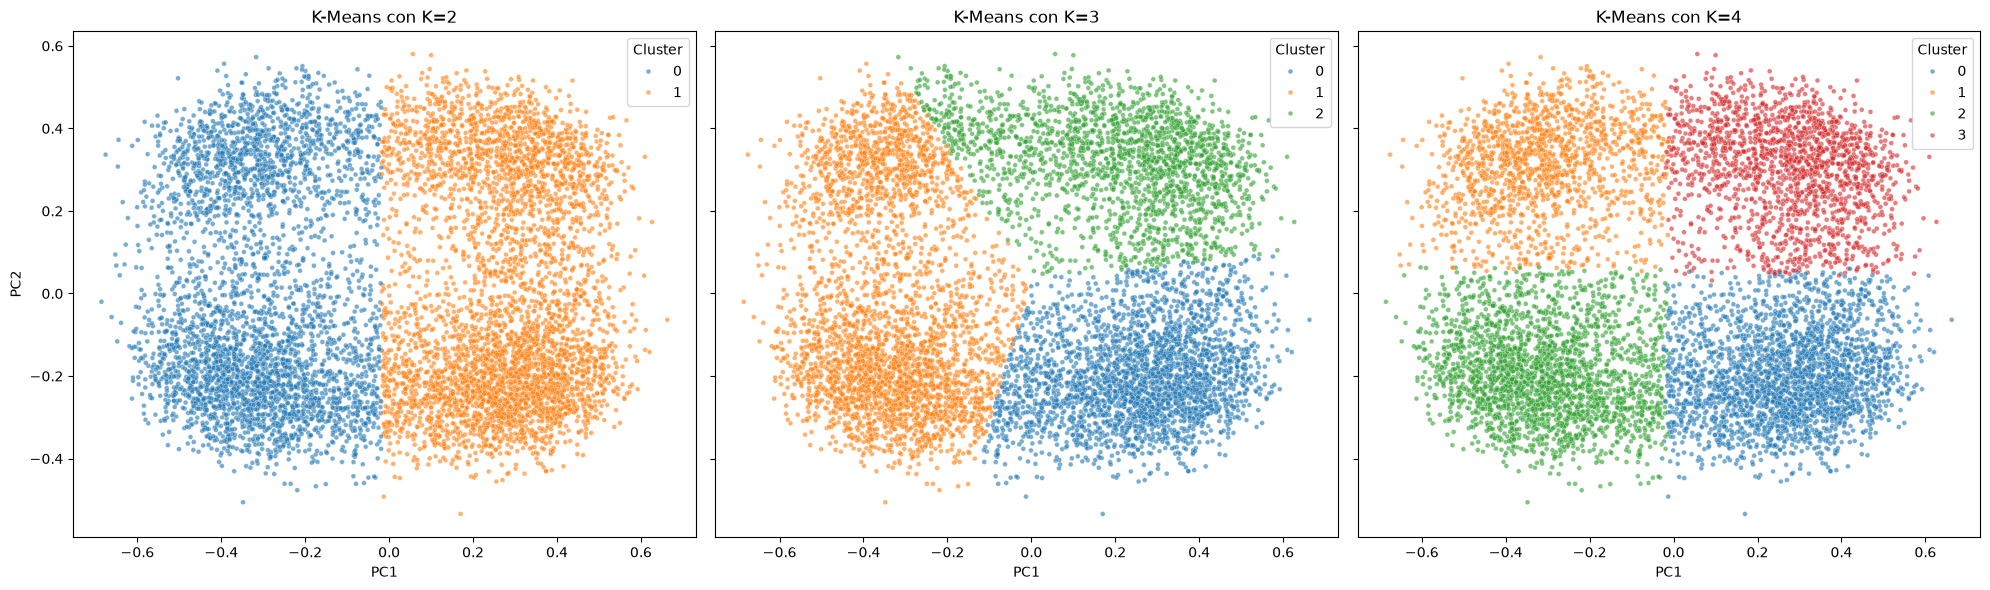

In [14]:
ks = [2, 3, 4]

fig, axes = plt.subplots(
    1, 3,
    figsize=(20, 6),
    sharex=True,
    sharey=True
)

for ax, k in zip(axes, ks):

    sns.scatterplot(
        data=pca_df,
        x="PC1",
        y="PC2",
        hue=f"cluster_k{k}",
        palette="tab10",
        alpha=0.6,
        s=12,
        ax=ax
    )

    ax.set_title(f"K-Means con K={k}")
    ax.legend(title="Cluster")

plt.tight_layout()
plt.show()

In [15]:
for k in [2, 3, 4]:

    print(f"\n{'=' * 50}")
    print(f"CARACTERIZACIÓN DE CLUSTERS - K={k}")
    print(f"{'=' * 50}")

    cluster_col = f"cluster_k{k}"

    # Tamaño de cada cluster
    print("\nTamaño de los clusters:")

    display(
        pd.DataFrame({
            "usuarios": pca_df[cluster_col].value_counts(),
            "porcentaje": (
                pca_df[cluster_col]
                .value_counts(normalize=True) * 100
            )
        }).sort_index().round(2)
    )

    # Preferencias de juego
    print("\nPreferencias de juego:")

    display(
        pca_df.groupby(cluster_col)[style_cols]
        .mean()
        .round(3)
    )

    # Distribución del estilo predominante
    print("\nEstilo de juego predominante:")

    display(
        pd.crosstab(
            pca_df[cluster_col],
            pca_df["estilo_dominante"],
            normalize="index"
        ).mul(100).round(2)
    )

    # Distribución de dispositivos
    print("\nDistribución de dispositivos:")

    display(
        pd.crosstab(
            pca_df[cluster_col],
            pca_df["dispositivo"],
            normalize="index"
        ).mul(100).round(2)
    )


CARACTERIZACIÓN DE CLUSTERS - K=2

Tamaño de los clusters:


,usuarios,porcentaje
cluster_k2,,
0,3762,46.88
1,4262,53.12



Preferencias de juego:


,pct_casino,pct_deportes_prepartido,pct_deportes_en_vivo
cluster_k2,,,
0,0.384,0.318,0.298
1,0.394,0.318,0.288



Estilo de juego predominante:


estilo_dominante,pct_casino,pct_deportes_en_vivo,pct_deportes_prepartido
cluster_k2,,,
0,40.80,28.63,30.57
1,42.47,27.45,30.08


... (14 outputs left out)


Estilo de juego predominante:


estilo_dominante,pct_casino,pct_deportes_en_vivo,pct_deportes_prepartido
cluster_k4,,,
0,6.72,44.12,49.16
1,94.66,3.22,2.12
2,6.85,44.84,48.31
3,96.23,2.12,1.65



Distribución de dispositivos:


dispositivo,android,ios,web
cluster_k4,,,
0,66.11,18.00,15.89
1,37.81,36.30,25.89
2,65.05,18.82,16.13
3,37.89,35.00,27.11


In [16]:
# Variables adicionales de comportamiento
behavior_cols = [
    "antiguedad_dias",
    "sesiones_semana",
    "eventos_por_sesion",
    "ticket_promedio_usd",
    "hora_pico"
]

# Estadísticas por cluster
perfil_clusters = pca_df.groupby("cluster_k4")[
    behavior_cols
].agg(["mean", "median", "std"])

display(perfil_clusters.round(2))

antiguedad_dias                sesiones_semana                \
                      mean median     std            mean median    std   
cluster_k4                                                                
0                   485.52  417.0  313.49            4.88    4.0   3.28   
1                   435.06  368.5  318.12            8.66    5.2  19.87   
2                   439.38  366.0  331.18            4.85    4.0   3.23   
3                   483.82  414.0  316.99            6.11    5.0   4.16   

           eventos_por_sesion              ticket_promedio_usd                \
                         mean median   std                mean median    std   
cluster_k4                                                                     
0                       20.57   20.1  4.43               17.28  11.44  18.77   
1                       29.70   29.5  5.75               15.03   9.96  18.77   
2                       30.79   30.7  5.84               17.31  11.00  19.99   
3                       19.45   18.9  4.41               14.51  10.04  15.55   

           hora_pico               
                mean median   std  
cluster_k4                         
0              16.41   18.0  6.42  
1              13.68   19.0  9.17  
2              16.54   19.0  6.45  
3              13.88   19.0  9.12

In [17]:
for col in ["dispositivo", "marca", "pais"]:

    print(f"\nDistribución de {col} por cluster")

    display(
        pd.crosstab(
            pca_df["cluster_k4"],
            pca_df[col],
            normalize="index"
        ).mul(100).round(2)
    )


Distribución de dispositivo por cluster


dispositivo,android,ios,web
cluster_k4,,,
0,66.11,18.00,15.89
1,37.81,36.30,25.89
2,65.05,18.82,16.13
3,37.89,35.00,27.11



Distribución de marca por cluster


marca,A,B
cluster_k4,,
0,58.45,41.55
1,59.73,40.27
2,61.10,38.90
3,59.99,40.01



Distribución de pais por cluster


pais,P1,P2
cluster_k4,,
0,46.78,53.22
1,49.11,50.89
2,48.83,51.17
3,47.26,52.74


In [18]:
from scipy.stats import spearmanr

# Relación entre antigüedad y eventos por sesión
grupos = {
    "Todos los usuarios": pca_df,
    "Deportes": pca_df[pca_df["cluster_k4"].isin([0, 2])],
    "Casino": pca_df[pca_df["cluster_k4"].isin([1, 3])]
}

for nombre, grupo in grupos.items():
    rho, p_value = spearmanr(
        grupo["antiguedad_dias"],
        grupo["eventos_por_sesion"],
        nan_policy="omit"
    )

    print(
        f"{nombre}: "
        f"Spearman = {rho:.3f}, "
        f"p-value = {p_value:.4g}"
    )

Todos los usuarios: Spearman = -0.084, p-value = 3.805e-14
Deportes: Spearman = -0.089, p-value = 4.312e-10
Casino: Spearman = -0.079, p-value = 9.957e-06


## Conclusiones del análisis
El análisis de los 8.024 embeddings de 64 dimensiones permitió identificar información relacionada con las preferencias de juego y los patrones de interacción de los usuarios.

La exploración mediante PCA mostró dos grandes regiones asociadas a las preferencias por casino y apuestas deportivas. Posteriormente, K-Means permitió obtener una segmentación de cuatro grupos: dos orientados principalmente a deportes y dos orientados a casino. Las diferencias entre estos subgrupos aparecen especialmente en el número de eventos por sesión.

También se identificó una asociación entre el dispositivo principal y las preferencias de juego. En cambio, la marca y el país presentan distribuciones similares entre los clusters. La antigüedad de los usuarios tiene una asociación negativa, aunque débil, con los eventos por sesión.

Desde la perspectiva de negocio, los embeddings son un insumo útil para explorar segmentos de usuarios en CRM y para diseñar recomendaciones diferenciadas en el lobby. Sin embargo, la segmentación debe validarse posteriormente con métricas de negocio y experimentos antes de incorporarse como criterio único de recomendación.

Los resultados son exploratorios y describen asociaciones entre los embeddings y las variables disponibles. No permiten establecer relaciones causales ni reconstruir los detalles del entrenamiento original.